# Market regimes

Risk models behave differently in calm and stressed markets. This note labels each day as calm, normal or stress, and measures how the VaR methods of [`04_backtest`](04_backtest.ipynb) and the volatility models of [`02_volatility`](02_volatility.ipynb) perform in each regime (gold tables `fact_regime`, `fact_regime_profile`, `fact_regime_transition`, `fact_backtest_regime` and `fact_forecast_regime`, produced by [`pipeline/regimes.py`](../pipeline/regimes.py)).

**Features**, at each close: the 22-day volatility of the three equity indices (in logs), their 22-day return, the average pairwise correlation of their daily returns over 63 days, and the VIX (in logs).

**Models.** A three-state Gaussian hidden Markov model (HMM; Hamilton, 1989; Rabiner, 1989), whose transition matrix makes regimes persist, and a Gaussian mixture (GMM) on the same features, which treats every day independently. States are ordered by average volatility and named calm, normal and stress.

**Two fits.** The *full-history* HMM is fitted on every day from 2008 and labels each day with smoothed probabilities, which use later data: it describes the past and is used for analysis only. The *walk-forward* HMM is refitted every January from 2012 on past data, standardised with past statistics only, and filtered forward: its regime on a day uses nothing after that day's close.

**Starting point of the fit.** EM starts from k-means means and a transition matrix with 0.95 on its diagonal. Random starts reach several optima with different labellings: the best of ten random starts changed when one day of data was added, and the highest likelihood found over fifty isolates crisis peaks (a third of 2008 in stress) rather than stressed markets. With the fixed start, adding a day leaves 99.96% of the full-history labels unchanged. The fixed start does not reach the highest likelihood, so the labels are a stable description of the data, not its best Gaussian fit.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists())
GOLD = ROOT / "data" / "gold"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
REGIME_NAMES = {0: "calm", 1: "normal", 2: "stress"}
REGIME_SHADES = {1: "#e6e5e1", 2: "#f6cfcb"}
METHOD_COLORS = {"hs": "#a9a8a3", "param_champion": "#2a78d6", "fhs": "#eb6834"}
METHOD_NAMES = {
    "hs": "Historical simulation",
    "param_ewma": "Parametric (EWMA)",
    "param_garch": "Parametric (GARCH)",
    "param_champion": "Parametric (GJR)",
    "fhs": "Filtered historical simulation",
}
plt.rcParams.update(
    {
        "figure.figsize": (9, 3.6),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "lines.linewidth": 1.5,
        "legend.frameon": False,
        "font.size": 9,
    }
)

regimes = pd.read_parquet(GOLD / "fact_regime.parquet").assign(date=lambda d: pd.to_datetime(d["date"]))
profile = pd.read_parquet(GOLD / "fact_regime_profile.parquet")
transitions = pd.read_parquet(GOLD / "fact_regime_transition.parquet")
by_regime = pd.read_parquet(GOLD / "fact_backtest_regime.parquet")
losses = pd.read_parquet(GOLD / "fact_forecast_regime.parquet")
market = pd.read_parquet(GOLD / "fact_market.parquet").assign(date=lambda d: pd.to_datetime(d["date"]))


def labels(method: str, fit: str) -> pd.Series:
    rows = regimes[(regimes["method"] == method) & (regimes["fit"] == fit)]
    return rows.set_index("date")["regime_id"]


full, live, mixture = (
    labels("hmm", "full_history"),
    labels("hmm", "walk_forward"),
    labels("gmm", "full_history"),
)
print(
    f"Regimes from {full.index.min():%d %b %Y} to {full.index.max():%d %b %Y} ({len(full)} days); walk-forward from {live.index.min():%d %b %Y}"
)

Regimes from 28 Feb 2008 to 22 Oct 2026 (4818 days); walk-forward from 02 Jan 2012


## 1. Choosing the features and the number of regimes

The guide also lists the yield curve slope. With it, the HMM's middle state became the steep-curve years of the early 2010s (a 2-point slope, spells of about 645 days): a rates era rather than a market condition, and the HMM and GMM agreed on only 13% of days. The slope moves too slowly to describe a regime that lasts weeks, so it was dropped. BIC (Schwarz, 1978) keeps falling from two to five states, as it usually does on long financial series, so it does not select the number of regimes; three were kept because each has a clear economic meaning.

In [2]:
def profile_table(method: str, fit: str) -> pd.DataFrame:
    rows = (
        profile[(profile["method"] == method) & (profile["fit"] == fit)].set_index("regime_id").sort_index()
    )
    table = rows[
        ["share_of_days", "mean_duration_days", "volatility", "return_22d", "correlation_63d", "vix"]
    ]
    return table.rename(index=REGIME_NAMES)


print("Full-history HMM")
display(profile_table("hmm", "full_history").round(3))
print("Walk-forward HMM (from 2012)")
display(profile_table("hmm", "walk_forward").round(3))
print("Full-history Gaussian mixture")
profile_table("gmm", "full_history").round(3)

Full-history HMM


,share_of_days,mean_duration_days,volatility,return_22d,correlation_63d,vix
regime_id,,,,,,
calm,0.418,80.640,0.115,0.017,0.643,14.581
normal,0.402,56.912,0.190,0.019,0.772,20.081
stress,0.180,41.286,0.313,-0.050,0.668,31.216


Walk-forward HMM (from 2012)


,share_of_days,mean_duration_days,volatility,return_22d,correlation_63d,vix
regime_id,,,,,,
calm,0.574,53.537,0.131,0.012,0.663,15.152
normal,0.196,25.828,0.185,0.018,0.799,18.716
stress,0.230,25.912,0.204,-0.009,0.627,23.210


Full-history Gaussian mixture


,share_of_days,mean_duration_days,volatility,return_22d,correlation_63d,vix
regime_id,,,,,,
calm,0.484,17.289,0.119,0.017,0.661,14.907
normal,0.364,11.464,0.208,0.019,0.767,21.029
stress,0.152,10.429,0.310,-0.062,0.658,32.381


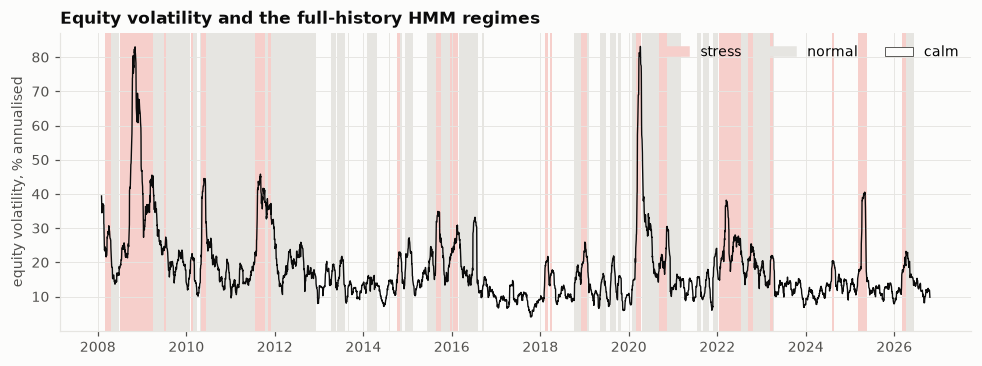

In [3]:
equity_vol = (
    market[market["instrument_id"].isin(["CAC40", "SX5E", "SPX"])]
    .pivot(index="date", columns="instrument_id", values="vol_22d")
    .mean(axis=1)
)
fig, ax = plt.subplots(figsize=(9, 3.4))
spells = full.groupby((full != full.shift()).cumsum())
for _, spell in spells:
    regime = spell.iloc[0]
    if regime in REGIME_SHADES:
        ax.axvspan(spell.index[0], spell.index[-1], color=REGIME_SHADES[regime], linewidth=0, zorder=0)
ax.plot(equity_vol.index, equity_vol * 100, color=INK, linewidth=0.9)
ax.set_ylabel("equity volatility, % annualised")
ax.set_title("Equity volatility and the full-history HMM regimes")
ax.legend(
    handles=[
        Patch(color=REGIME_SHADES[2], label="stress"),
        Patch(color=REGIME_SHADES[1], label="normal"),
        Patch(facecolor=SURFACE, edgecolor=INK2, linewidth=0.6, label="calm"),
    ],
    loc="upper right",
    ncol=3,
)
plt.tight_layout()
plt.show()

The full-history HMM finds a calm regime on 42% of days (equity volatility 11.5%, VIX 14.6), a normal regime on 40% (volatility 19.0%, the highest equity correlation, 0.77) and a stress regime on 18% (volatility 31.3%, VIX 31.2, a 22-day return of −5.0%). Regimes persist: an average calm spell lasts 81 days, a stress spell 41. The Gaussian mixture finds similar clouds but switches every 10 to 17 days on average, because it ignores what happened the day before; the HMM's transition matrix is what makes the labels usable. The walk-forward HMM, which only knows the past, switches more often (stress spells of 26 days against 41) and its stress state is less distinct: 20.4% volatility on average against 18.5% in its normal state, with the lowest equity correlation (0.63).

## 2. Do the regimes match known episodes, and do they persist?

In [4]:
years = [2008, 2011, 2015, 2018, 2020, 2022, 2025, full.index.max().year]
composition = pd.DataFrame(
    {
        "stress share, full history": {year: (full[str(year)] == 2).mean() for year in years},
        "stress share, walk-forward": {
            year: (live[str(year)] == 2).mean() if year >= live.index.min().year else np.nan for year in years
        },
        "calm share, full history": {year: (full[str(year)] == 0).mean() for year in years},
    }
).round(2)
onset = {
    name: series["2020-02-01":"2020-04-30"][series["2020-02-01":"2020-04-30"] == 2].index.min()
    for name, series in [("full history", full), ("walk-forward", live)]
}
common = full.index.intersection(live.index)
print(
    f"First stress day of 2020: full history {onset['full history']:%d %b %Y}, walk-forward {onset['walk-forward']:%d %b %Y}"
)
print(
    f"Agreement since {live.index.min().year}: same regime on {(full[common] == live[common]).mean():.1%} of days, same stress/not-stress call on {((full[common] == 2) == (live[common] == 2)).mean():.1%}"
)
print(
    f"HMM and Gaussian mixture (full history) agree on {(full == mixture.reindex(full.index)).mean():.1%} of days"
)
composition

First stress day of 2020: full history 27 Feb 2020, walk-forward 28 Feb 2020
Agreement since 2012: same regime on 71.0% of days, same stress/not-stress call on 85.3%
HMM and Gaussian mixture (full history) agree on 86.9% of days


,"stress share, full history","stress share, walk-forward","calm share, full history"
2008,0.78,NaN,0.00
2011,0.28,NaN,0.00
2015,0.16,0.01,0.29
2018,0.21,0.39,0.63
2020,0.32,0.46,0.07
2022,0.60,0.73,0.03
2025,0.21,0.10,0.79
2026,0.12,0.14,0.64


In [5]:
matrix = transitions[(transitions["method"] == "hmm") & (transitions["fit"] == "full_history")].pivot(
    index="regime_from", columns="regime_to", values="probability"
)
matrix = matrix.rename(index=REGIME_NAMES, columns=REGIME_NAMES)
print("Day-to-day transition frequencies, full-history HMM (rows: today, columns: tomorrow)")
matrix.round(3)

Day-to-day transition frequencies, full-history HMM (rows: today, columns: tomorrow)


regime_to,calm,normal,stress
regime_from,,,
calm,0.988,0.008,0.003
normal,0.011,0.982,0.007
stress,0.005,0.020,0.976


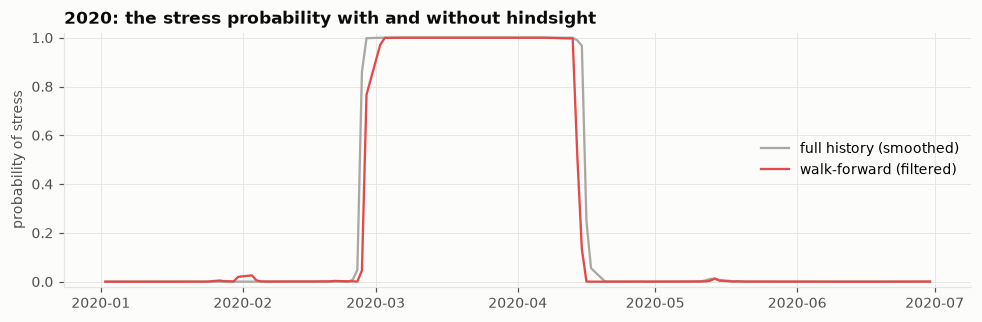

In [6]:
window = slice("2020-01-01", "2020-06-30")
fig, ax = plt.subplots(figsize=(9, 3.0))
for name, fit, color in [
    ("full history (smoothed)", "full_history", "#a9a8a3"),
    ("walk-forward (filtered)", "walk_forward", "#e34948"),
]:
    rows = regimes[(regimes["method"] == "hmm") & (regimes["fit"] == fit)].set_index("date").loc[window]
    ax.plot(rows.index, rows["p_stress"], color=color, label=name)
ax.set_ylim(-0.02, 1.02)
ax.set_ylabel("probability of stress")
ax.set_title("2020: the stress probability with and without hindsight")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

The known episodes are in stress: 78% of 2008, 60% of 2022 in the full-history fit (73% walk-forward), and the 2020 crash, which the full-history fit enters on 27 February and the walk-forward fit on 28 February; both leave stress in mid-April. Regimes are sticky: the full-history HMM stays in its regime from one day to the next with a frequency of 0.976 to 0.988. Since 2012 the two fits give the same regime on 71.0% of days and the same stress call on 85.3%. The largest gaps are 2021 (59% stress for the walk-forward fit, none with hindsight) and 2024 (51% against 5%): the models refitted from 2021 put long spells of moderate volatility and low equity correlation in their stress state (2021: volatility 14.5%, correlation 0.63; 2024: 12.4%, 0.50). A regime label is relative to the history and the fit, so any use of regimes must say which fit it uses.

## 3. VaR exceptions by regime

Each exception of the 1-day VaR 99% is attributed to the regime at the close when the VaR was computed, so the walk-forward attribution uses only information available at that time. A correct VaR is exceeded on 1% of days in every regime; Kupiec's test (1995) checks each cell.

In [7]:
def exceptions_table(fit: str) -> pd.DataFrame:
    rows = by_regime[by_regime["fit"] == fit].assign(regime=lambda d: d["regime_id"].map(REGIME_NAMES))
    cells = rows.assign(
        cell=rows["n_exceptions"].astype(str)
        + " / "
        + rows["expected_exceptions"].round(1).astype(str)
        + " (p "
        + rows["kupiec_p"].round(3).astype(str)
        + ")"
    )
    table = cells.pivot(index="method_id", columns="regime", values="cell")[["calm", "normal", "stress"]]
    return table.rename(index=METHOD_NAMES)


days = by_regime[by_regime["method_id"] == "fhs"].set_index(["fit", "regime_id"])["n_days"]
print(
    "Exceptions / expected (Kupiec p), full-history regimes; days per regime:",
    {REGIME_NAMES[r]: int(days[("full_history", r)]) for r in range(3)},
)
display(exceptions_table("full_history"))
print(
    "Same, walk-forward regimes; days per regime:",
    {REGIME_NAMES[r]: int(days[("walk_forward", r)]) for r in range(3)},
)
exceptions_table("walk_forward")

Exceptions / expected (Kupiec p), full-history regimes; days per regime: {'calm': 1996, 'normal': 1317, 'stress': 511}


regime,calm,normal,stress
method_id,,,
Filtered historical simulation,20 / 20.0 (p 0.993),16 / 13.2 (p 0.448),2 / 5.1 (p 0.115)
Historical simulation,18 / 20.0 (p 0.654),19 / 13.2 (p 0.13),18 / 5.1 (p 0.0)
Parametric (GJR),28 / 20.0 (p 0.088),20 / 13.2 (p 0.079),6 / 5.1 (p 0.7)
Parametric (EWMA),39 / 20.0 (p 0.0),23 / 13.2 (p 0.014),12 / 5.1 (p 0.009)
Parametric (GARCH),24 / 20.0 (p 0.378),21 / 13.2 (p 0.046),11 / 5.1 (p 0.023)


Same, walk-forward regimes; days per regime: {'calm': 2193, 'normal': 749, 'stress': 881}


regime,calm,normal,stress
method_id,,,
Filtered historical simulation,28 / 21.9 (p 0.212),7 / 7.5 (p 0.856),3 / 8.8 (p 0.023)
Historical simulation,33 / 21.9 (p 0.027),7 / 7.5 (p 0.856),15 / 8.8 (p 0.057)
Parametric (GJR),36 / 21.9 (p 0.006),7 / 7.5 (p 0.856),11 / 8.8 (p 0.475)
Parametric (EWMA),50 / 21.9 (p 0.0),9 / 7.5 (p 0.591),15 / 8.8 (p 0.057)
Parametric (GARCH),37 / 21.9 (p 0.003),6 / 7.5 (p 0.571),13 / 8.8 (p 0.185)


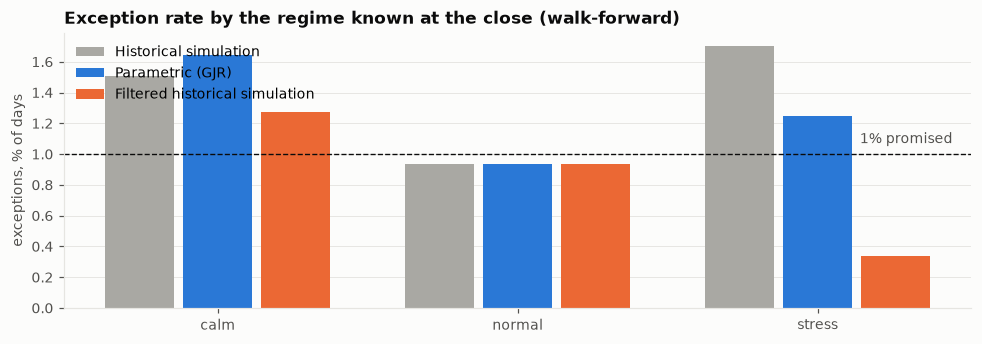

In [8]:
rows = by_regime[(by_regime["fit"] == "walk_forward") & by_regime["method_id"].isin(METHOD_COLORS)]
rates = rows.assign(rate=rows["n_exceptions"] / rows["n_days"] * 100).pivot(
    index="regime_id", columns="method_id", values="rate"
)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.set_axisbelow(True)
width = 0.26
for offset, method in enumerate(METHOD_COLORS):
    positions = np.arange(3) + (offset - 1) * width
    ax.bar(
        positions, rates[method], width=width - 0.03, color=METHOD_COLORS[method], label=METHOD_NAMES[method]
    )
ax.axhline(1.0, color=INK, linewidth=0.9, linestyle="--")
ax.text(2.45, 1.05, "1% promised", color=INK2, ha="right", va="bottom")
ax.set_xticks(range(3), [REGIME_NAMES[r] for r in range(3)])
ax.set_ylabel("exceptions, % of days")
ax.set_title("Exception rate by the regime known at the close (walk-forward)")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

With hindsight regimes, historical simulation is exceeded 18 times for 5.1 expected in stress (3.5% of days, Kupiec p < 0.001): it uses the last 250 days with equal weights, so when markets turn, its VaR still reflects the calm year behind it. With the regimes known at the close the pattern is weaker (15 for 8.8 in stress, p = 0.057), because the walk-forward stress state also holds quiet spells. The normal VaRs fail the other way: parametric GJR is exceeded 36 times for 21.9 expected in walk-forward calm regimes (p = 0.006) and close to 1% in stress (11 for 8.8). With low volatility, a normal distribution leaves no room for a sudden shock out of a quiet market. Filtered historical simulation is close to 1% in calm and normal regimes (28 for 21.9, p = 0.21; 7 for 7.5) and conservative in stress: 3 exceptions for 8.8 expected walk-forward (p = 0.023) and 2 for 5.1 with hindsight (p = 0.12).

## 4. Volatility forecast errors by regime

Mean QLIKE (Patton, 2011) of each model of [`02_volatility`](02_volatility.ipynb) on the 5-day volatility of the book, by the regime on the forecast date.

In [9]:
book = losses[(losses["fit"] == "walk_forward") & (losses["series_id"] == "book")]
table = book.pivot(index="model_id", columns="regime_id", values="qlike").rename(columns=REGIME_NAMES)
counts = book.drop_duplicates("regime_id").set_index("regime_id")["n_days"].rename(index=REGIME_NAMES)
print("Mean QLIKE of the book's forecasts by walk-forward regime (lower is better); days:", counts.to_dict())
display(table.sort_values("stress").round(3))
best = losses[losses["fit"] == "walk_forward"].loc[
    lambda d: d.groupby(["series_id", "regime_id"])["qlike"].idxmin()
]
print("Lowest QLIKE by series and regime")
best.pivot(index="series_id", columns="regime_id", values="model_id").rename(columns=REGIME_NAMES)

Mean QLIKE of the book's forecasts by walk-forward regime (lower is better); days: {'calm': 1061, 'normal': 385, 'stress': 824}


regime_id,calm,normal,stress
model_id,,,
gjr,0.404,0.378,0.401
gru,0.415,0.331,0.419
garch,0.398,0.391,0.453
har,0.407,0.410,0.458
ewma,0.456,0.406,0.470
xgboost,0.431,0.384,0.476


Lowest QLIKE by series and regime


regime_id,calm,normal,stress
series_id,,,
CAC40,xgboost,xgboost,gjr
EUR_ZC10Y,gru,har,ewma
GOLD,gjr,har_range,har_range
SPX,xgboost,gru,gjr
SX5E,xgboost,xgboost,gjr
USD_CASH,gjr,gjr,garch
book,garch,gru,gjr


On the book, GJR-GARCH has the lowest QLIKE in stress (0.401, against 0.419 for the GRU and 0.458 for HAR); the GRU is lowest in normal regimes (0.331 against 0.378) and GARCH in calm ones (0.398 against 0.404). Five of the six models have a higher loss in calm than in normal regimes, consistent with the VaR exceptions above: shocks out of quiet markets are under-forecast. XGBoost is lowest in calm regimes on the three equity indices and has the highest loss on the book in stress. Across the seven series, GJR-GARCH has the lowest loss in stress on four (the book and the three equity indices). The champion chosen in [`02_volatility`](02_volatility.ipynb) holds where it matters for the VaR.

## 5. Conclusions and consequences

| Finding | Consequence |
|---|---|
| The HMM regimes match 2008, March 2020 (from 27 February) and 2022, and last 41 to 81 days on average, against 10 to 17 for a Gaussian mixture | Use the HMM; use the walk-forward fit for anything that must be known at the close |
| Random EM starts give different labellings, and the best of ten changed with one more day of data | EM starts from k-means and a persistent transition matrix: 99.96% of labels unchanged when a day is added |
| Historical simulation: 18 exceptions for 5.1 expected in stress with hindsight (p < 0.001), 15 for 8.8 walk-forward (p = 0.057) | Its failures come when risk rises, which confirms its rejection in [`04_backtest`](04_backtest.ipynb) |
| Filtered historical simulation: near 1% in calm and normal regimes, 3 exceptions for 8.8 in walk-forward stress (p = 0.023) | Confirms the recommended VaR; conservative, not short, in stress |
| Parametric GJR: 36 exceptions for 21.9 expected in calm regimes (p = 0.006) | Normal tails miss shocks out of quiet markets; the empirical tails of FHS correct it |
| GJR-GARCH has the lowest QLIKE on the book in stress regimes | The volatility champion holds in stress; other models' gains are in calm and normal markets |
| 2021 and 2024: over half the days in stress for the walk-forward fit, little with hindsight | The walk-forward stress state also holds low-correlation spells; regime labels depend on the fit, so always state it |

**Limits.** Three states are imposed rather than selected (BIC keeps falling with more states); the fixed EM start gives stable labels but not the highest likelihood; the features describe equity markets only, not rates or credit; emissions are Gaussian; the walk-forward model is refitted once a year and its stress state is less distinct than the full-history one. The regimes are used to analyse the models, not as their inputs. Statistical jump models (Aydınhan et al., 2024; Shu, Yu and Mulvey, 2024), which penalise regime switches directly, are a recent alternative with more stable online labels.

## References

- Ang, A., & Timmermann, A. (2012). Regime changes and financial markets. *Annual Review of Financial Economics*, 4, 313–337.
- Aydınhan, A. O., Kolm, P. N., Mulvey, J. M., & Shu, Y. (2024). Identifying patterns in financial markets: Extending the statistical jump model for regime identification. *Annals of Operations Research*. https://doi.org/10.1007/s10479-024-06035-z
- Hamilton, J. D. (1989). A new approach to the economic analysis of nonstationary time series and the business cycle. *Econometrica*, 57(2), 357–384.
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *Journal of Derivatives*, 3(2), 73–84.
- Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics*, 160(1), 246–256.
- Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE*, 77(2), 257–286.
- Schwarz, G. (1978). Estimating the dimension of a model. *Annals of Statistics*, 6(2), 461–464.
- Shu, Y., Yu, C., & Mulvey, J. M. (2024). Downside risk reduction using regime-switching signals: A statistical jump model approach. *Journal of Asset Management*. https://doi.org/10.1057/s41260-024-00376-x